# Layered-earth calibration and interval coverage

**Level 2 — Applied analysis**  
**Prerequisites:** Level 1 and arrays/logarithms; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.

## Data

Measured QC-only record plus a separate seeded synthetic calibration artifact; never merge these evidence classes.

## Method

This artifact is explicitly synthetic: a 1D two-layer earth, `[180,20] Ω·m`, upper thickness 450 m, 24 frequencies, 48 independent noisy realizations and 128 bootstrap draws per realization. Empirical interval coverage is `C=N⁻¹Σ1[ρtrue∈CI]`; the independent unit is the realization, not each bootstrap draw. Compare coverage with the 95% nominal level and stored Wilson bounds, then inspect interval width in Ω·m. The interval is conditional on fixed thickness, independent Gaussian real/imaginary errors, bounds and regularization. It is not a field confidence guarantee; high apparent coverage can coexist with biased or weakly resolved layers.

Parameters are log-resistivities: positive by construction, with equal steps representing equal multiplicative changes. Complex residuals use per-real-component sigma; real and imaginary parts both inform the fit. Frequencies are not independent depth samples: sensitivity kernels overlap, so one period does not identify one interface. Local sensitivity and coverage remain conditional on the fixed parameterization and cannot rule out global equivalence.

## Results

Read the physical axes and units; distinguish data fit, error against synthetic truth and agreement with analyst labels. Recomputed values must agree with the serialized receipt. A plotted model alone does not establish uniqueness, field transfer or resolution.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib', 'scipy']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Inspect synthetic calibration provenance and independent realization rows.
import json
from pathlib import Path
cal=json.loads((root/"data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8"))
print(cal["kind"],cal["calibration_model"],"Ω·m; thickness",cal["fixed_thickness_m"],"m; frequencies",len(cal["frequencies_hz"]))
print("realizations",cal["realizations"],"bootstrap each",cal["bootstrap_samples_per_realization"],"nominal",cal["confidence"],"coverage",cal["coverage_per_layer"])

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
independent_seeded_conditional_bootstrap_coverage [180.0, 20.0] Ω·m; thickness [450.0] m; frequencies 24
realizations 48 bootstrap each 128 nominal 0.95 coverage [0.875, 1.0]


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

coverage [0.875 1.   ] ; median interval width Ω·m [44.96804628  1.67527305]


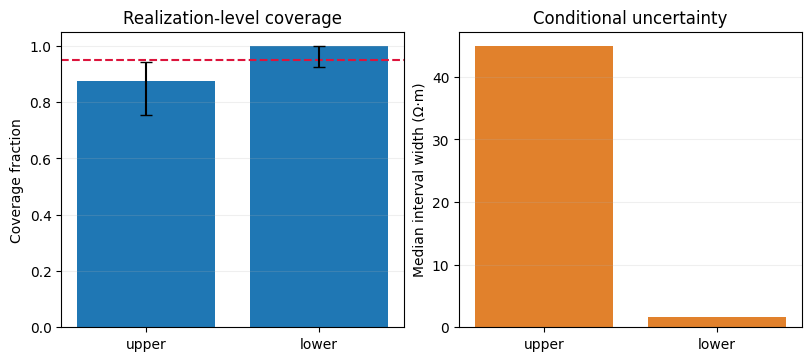

In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Recompute coverage and median interval widths from the 48 recorded fits.
import matplotlib.pyplot as plt
rows=cal["rows"]; truth=np.asarray(cal["calibration_model"],float); cover=np.asarray([r["covered"] for r in rows],bool); ci=np.asarray([r["interval_ohm_m"] for r in rows],float)
cov=cover.mean(0); width=np.median(ci[:,1,:]-ci[:,0,:],axis=0); print("coverage",cov,"; median interval width Ω·m",width)
fig,ax=plt.subplots(1,2,figsize=(8,3.5),constrained_layout=True); x=np.arange(2); ax[0].bar(x,cov); ax[0].axhline(cal["confidence"],ls="--",color="crimson"); ax[0].errorbar(x,cov,yerr=[np.maximum(0,cov-np.asarray(cal["coverage_wilson95_lower"])),np.maximum(0,np.asarray(cal["coverage_wilson95_upper"])-cov)],fmt="none",capsize=4,color="black"); ax[0].set(xticks=x,xticklabels=["upper","lower"],ylim=(0,1.05),ylabel="Coverage fraction",title="Realization-level coverage")
ax[1].bar(x,width,color="#e1812c"); ax[1].set(xticks=x,xticklabels=["upper","lower"],ylabel="Median interval width (Ω·m)",title="Conditional uncertainty"); [a.grid(axis="y",alpha=.2) for a in ax]; plt.show()

## Controlled regularization experiment

This is a reproducible **synthetic** 1D sounding, not a field interpretation. Generate a three-layer response with the repository forward operator, add seeded complex noise and fit only active periods. Every fourth frequency is withheld before fitting and used only for the reported validation residual. Thickness is fixed, so this experiment cannot test interface-depth recovery. A beta sweep exposes the fit/regularization trade-off under identical data, seed, start model and solver budget.

Synthetic truth: resistivity in ohm m, thickness in m and frequency in Hz. Holdout data are never passed to the solver. Local identifiability is conditional and is not a uniqueness proof.

beta=0; rho=[ 77.05   7.9  326.58] ohm m; active WRMS=0.855; held-out WRMS=1.010; identifiability=locally_resolved
beta=0.001; rho=[ 77.03   7.9  326.49] ohm m; active WRMS=0.855; held-out WRMS=1.011; identifiability=locally_resolved
beta=0.1; rho=[ 74.87   7.97 318.04] ohm m; active WRMS=0.861; held-out WRMS=1.029; identifiability=locally_resolved


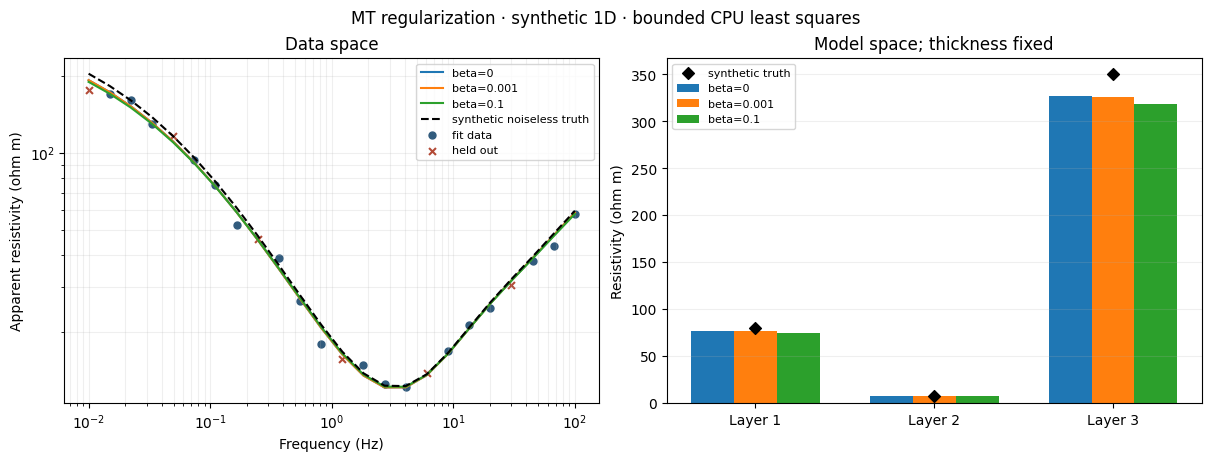

In [3]:
import sys
sys.path.insert(0,str(root/"data-pipeline"))
import electromagnetics as em
import numpy as np, matplotlib.pyplot as plt
f=np.logspace(-2,2,24); h=np.array([250.,600.]); truth=np.array([80.,8.,350.])
z0=em.impedance(truth,h,f); rng=np.random.default_rng(20261027); sigma=np.maximum(abs(z0)*.035,1e-12)
zobs=z0+sigma*(rng.normal(size=len(f))+1j*rng.normal(size=len(f))); active=np.arange(len(f))%4!=0
betas=[0.,.001,.1]; fits={}
for beta in betas:
 fits[beta]=em.invert_mt(h,f,zobs,sigma,active=active,initial=[100.,30.,150.],beta=beta,methods=("mt-lm",),max_nfev=120,record_every=20)["mt-lm"]
 q=fits[beta]["metrics"]; print(f"beta={beta:g}; rho={np.round(fits[beta]['model'],2)} ohm m; active WRMS={q['active_component_wrms']:.3f}; held-out WRMS={q['withheld_component_wrms']:.3f}; identifiability={fits[beta]['identifiability']['status']}")
fig,ax=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for b,r in fits.items(): ax[0].loglog(f,r["predicted"]["apparent"],label=f"beta={b:g}")
ax[0].loglog(f,abs(z0)**2/(em.MU*2*np.pi*f),"k--",label="synthetic noiseless truth")
for mask,mark,color,label in [(active,"o","#315b7d","fit data"),(~active,"x","#b34a36","held out")]: ax[0].scatter(f[mask],abs(zobs[mask])**2/(em.MU*2*np.pi*f[mask]),s=25,marker=mark,color=color,label=label)
ax[0].set(xlabel="Frequency (Hz)",ylabel="Apparent resistivity (ohm m)",title="Data space"); ax[0].grid(True,which="both",alpha=.2); ax[0].legend(fontsize=8)
x=np.arange(3); w=.24
for j,b in enumerate(betas): ax[1].bar(x+(j-1)*w,fits[b]["model"],w,label=f"beta={b:g}")
ax[1].scatter(x,truth,marker="D",color="black",label="synthetic truth",zorder=3); ax[1].set(xticks=x,xticklabels=["Layer 1","Layer 2","Layer 3"],ylabel="Resistivity (ohm m)",title="Model space; thickness fixed"); ax[1].grid(axis="y",alpha=.2); ax[1].legend(fontsize=8)
fig.suptitle("MT regularization · synthetic 1D · bounded CPU least squares"); plt.show()

## Summary

Conclusion is conditional on geometry, acquisition, noise model, split, parameterization and source rights. Preserve negative cases and name the next observation or control needed.

## References

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)